# Task: Edge Detection Filters 

**Goal:** apply every filter we covered to **your own picture**, compare the results, and explain what you see.

**Rules**
- Use your own image (a photo with clear objects and some texture works best, not a blank wall).
- Write the code yourself where you see `# TODO`. Hints are given, not solutions.
- Every plot needs a title. Use `plt.figure(figsize=...)` so images are readable.

**Submit:** this notebook with outputs visible + your answers.

## Part 0: Setup & Load Your Image

(256, 256)

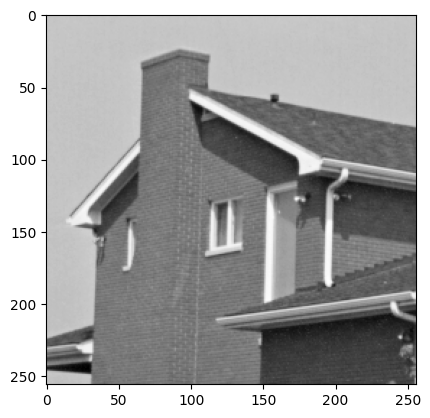

In [ ]:
import cv2 as cv 
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = r"D:\SkyXperts-Vision-Course\tasks\test images\4.1.05.tiff"

# TODO: load the image in grayscale and display it
# Hint: cv2.imread(..., cv2.IMREAD_GRAYSCALE), then plt.imshow(..., cmap="gray")
img=cv.imread(IMAGE_PATH,0) #0 is the numkerical representation for cv.IMREAD_GRAYSCALE
#1 is for colored 
#-1 is for unchanged (load as is)
plt.imshow(img, cmap="gray")

**Question 0:** What is the size (height × width) of your image? Why do we convert to grayscale before edge detection?

*Your answer:* 

the size if the img is 250*250 as is shown from the plot figure 

we convert the image to grayscale to reduce complexity of operations so instead of filtering 3 channels we filter only one and this is convenient because edge detection measures changes in intensity not color

## Part 1: Gradients (Sobel)

Compute the horizontal and vertical derivatives, then the magnitude and orientation.

Formulas: `mag = sqrt(gx² + gy²)` and `θ = arctan2(gy, gx)`

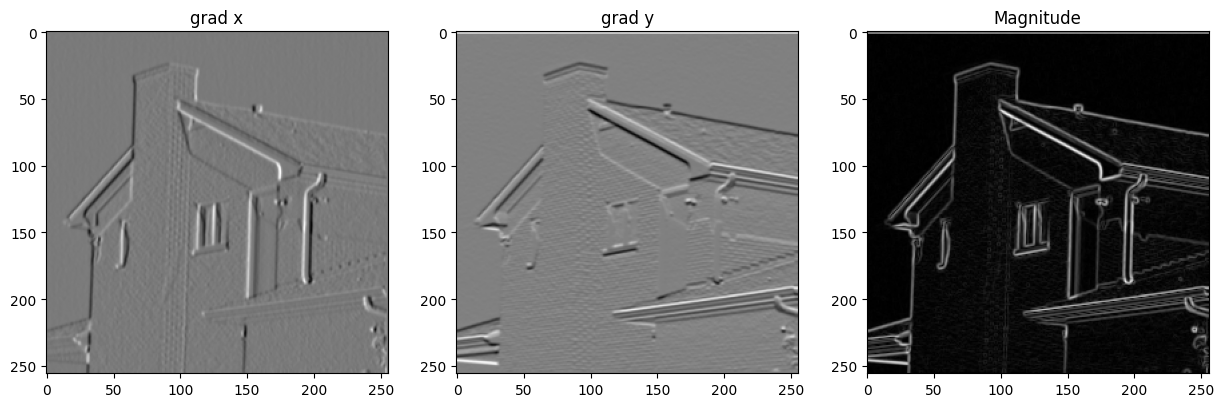

In [7]:
# TODO: compute grad_x and grad_y using cv2.Sobel with cv2.CV_64F and ksize=3
grad_x = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3) #result is stred as a 64-bit float to avoid overflow
grad_y = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)

# TODO: compute magnitude and orientation (in degrees)
magnitude = np.sqrt(grad_x**2 + grad_y**2)
orientation = np.arctan2(grad_y, grad_x) * (180 / np.pi)  # Convert radians to degrees

# TODO: show grad_x, grad_y and magnitude side by side (1 row, 3 columns)
plt.figure(figsize=(15, 5))
plt.subplot(1,3,1)
plt.imshow(grad_x, cmap="gray")
plt.title("grad x")
plt.subplot(1,3,2)
plt.imshow(grad_y, cmap="gray")
plt.title("grad y")
plt.subplot(1,3,3)
plt.imshow(magnitude, cmap="gray")
plt.title("Magnitude")
plt.show()

**Question 1a:** Which gradient (X or Y) highlights vertical lines in your image? Point out one object in your picture that proves it.

**Question 1b:** Why do we use `cv2.CV_64F` instead of the default `uint8` here? (Hint: what happens to negative values?)

*Your answers:* 

gradient x highlights vertical edges because the direction of the gradient is perpindicular to the edge , the chimney vertical edges are obvious in the displayed image of grad x but not as much in grad y

we represent the output of sobel grads in 64 bit floating points because the output values can be negative (which means intensity decreases in a specific diretion) so they can't fit the uint8 format anymore or the negative values won't be correctly represented and we lose i,portant info about edges 

## Part 2: Laplacian

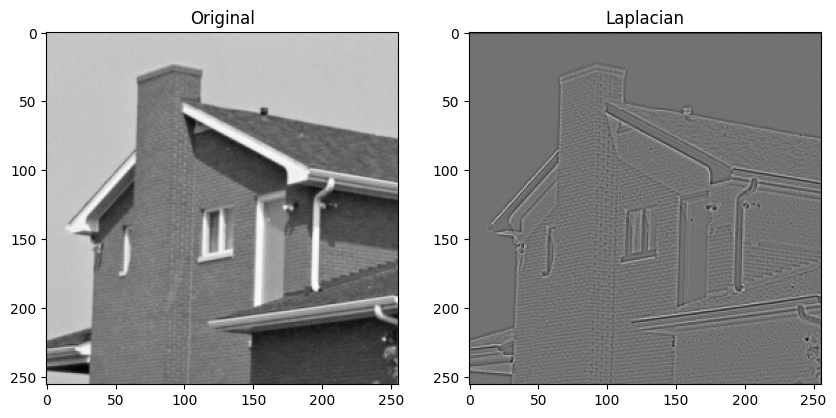

In [8]:
# TODO: apply the Laplacian and show it next to the original
laplacian = cv.Laplacian(img, cv.CV_64F)
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.subplot(1,2,2)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian")
plt.show()

**Question 2:** What is the difference between what the Laplacian gives you and what the Sobel gradients gave you? Does it tell you the edge direction?

*Your answer:* 

laplacian calculates the second derivative if intensity in the image and it calculates it in all directions unlike sobel which calculates horizontal and vertical rates of change seperately 

both outputs return edges of the img but the laplacian output is more integrated since both directions are combined

## Part 3: Canny

Try **three different threshold pairs** (low, high), for example a low pair, a medium pair, and a high pair.

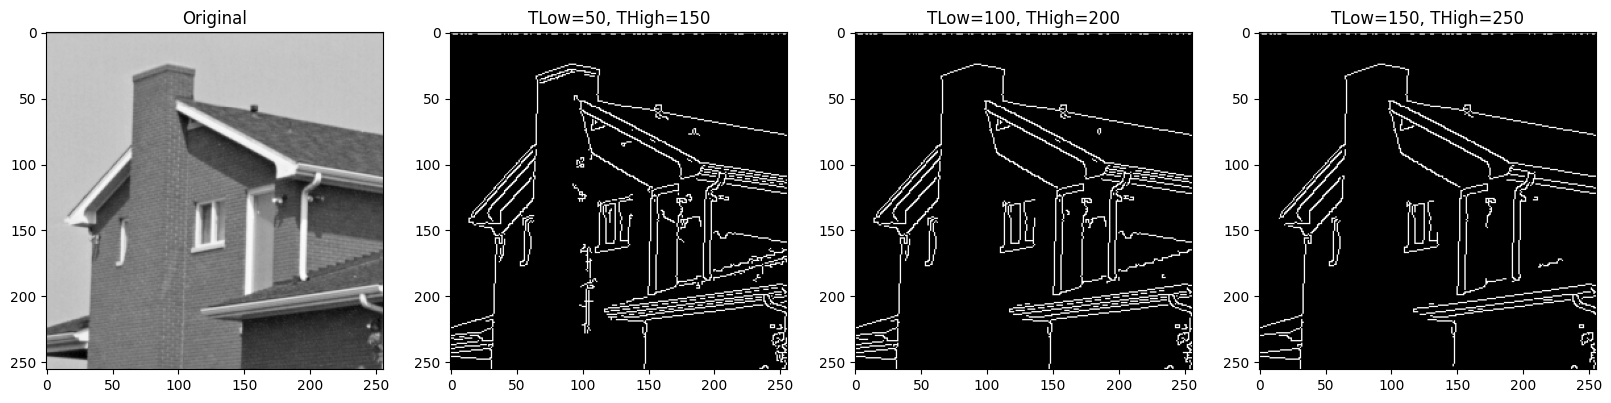

In [9]:
# TODO: run cv2.Canny with 3 different (low, high) threshold pairs
# TODO: show the original + the 3 results in one figure (1 row, 4 columns)
# Put the thresholds in each subplot title
canny1 = cv.Canny(img, 50, 150)
canny2 = cv.Canny(img, 100, 200)
canny3 = cv.Canny(img, 150, 250)
plt.figure(figsize=(20, 5))
plt.subplot(1,4,1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.subplot(1,4,2)
plt.imshow(canny1, cmap="gray")
plt.title("TLow=50, THigh=150")
plt.subplot(1,4,3)
plt.imshow(canny2, cmap="gray")
plt.title("TLow=100, THigh=200")
plt.subplot(1,4,4)
plt.imshow(canny3, cmap="gray")
plt.title("TLow=150, THigh=250")
plt.show()

**Question 3a:** What happens to the edges as you increase the thresholds?

**Question 3b:** List the 5 steps of the Canny pipeline in order.

*Your answers:* 

as we increase the thresholds the details of the image start to vanish and the edges decrease (look at the rooftop at the bottom right of the image)

1- Noise reduction by applying gaussian blur 

2- Applying the sobel filters to calculate the gradients in both directions to detect the edges 

3- Applying Non Maximum Suppression (NMS) to make the edge lines thinner, where for every pixel across an edge it is compared with two of its neighbors along the same direction and is only kept if its value is greater than both

4- Applying double thresholding (the two parameters we provide in the function) to identify strong and weak edges and eliminate noise from the image again where:

a pixel whose values is lower than the low threshold is discarded 

a pixel is kept if its value lies between both thresholds and is considered a part of a weak edge 

a pixel whose value is higher than the high threshold is kept and is considered part of a strong edge 

5- Edge tracking by Hysteresis , a weak edge is kept only if it is connected to a strong one 

## Part 4: Roberts & Prewitt (Your Own Kernels)

Define the kernels yourself as NumPy arrays and apply them with `cv2.filter2D`.

- Roberts: 2×2 kernels
- Prewitt: 3×3 kernels (X and Y)

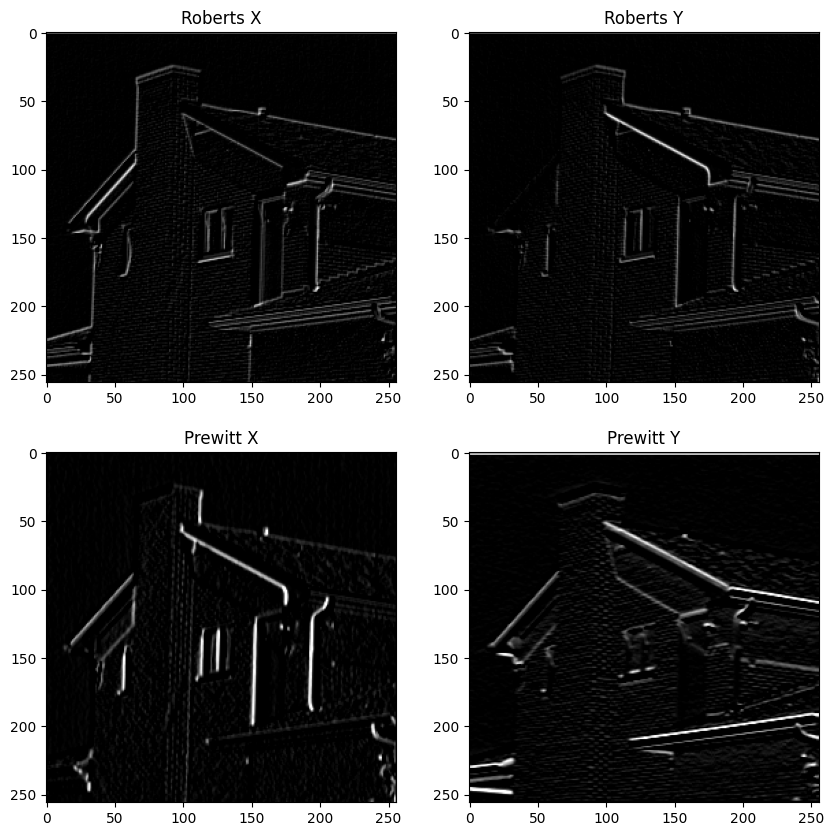

In [10]:
# TODO: define roberts_x, roberts_y, prewitt_x, prewitt_y
roberts_x= np.array([
    [1, 0],
    [0, -1]
])
roberts_y= np.array([
    [0, 1],
    [-1, 0]
])
prewitt_x= np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])
prewitt_y= np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
])

# TODO: apply each with cv2.filter2D(img, -1, kernel)
roberts_x= cv.filter2D(img, -1, roberts_x)
roberts_y= cv.filter2D(img, -1, roberts_y)
prewitt_x= cv.filter2D(img, -1, prewitt_x)
prewitt_y= cv.filter2D(img, -1, prewitt_y)

# TODO: show the 4 results in a 2x2 grid
plt.figure(figsize=(10, 10))
plt.subplot(2,2,1)
plt.imshow(roberts_x, cmap="gray")
plt.title("Roberts X")
plt.subplot(2,2,2)
plt.imshow(roberts_y, cmap="gray")
plt.title("Roberts Y")
plt.subplot(2,2,3)
plt.imshow(prewitt_x, cmap="gray")
plt.title("Prewitt X")
plt.subplot(2,2,4)
plt.imshow(prewitt_y, cmap="gray")
plt.title("Prewitt Y")
plt.show()

**Question 4:** Which one (Roberts or Prewitt) looks noisier on your image? Why do you think that is (think about kernel size)?

*Your answer:* 

Honestly none of the images look noisy there are clear edges that apply to the function of each filter but as for the kernel size the roberts images should be noisier since the kernel size is 2*2 making it more likely to pick up on tiny fluctuations 

## Part 5: Sobel 3×3 vs 5×5

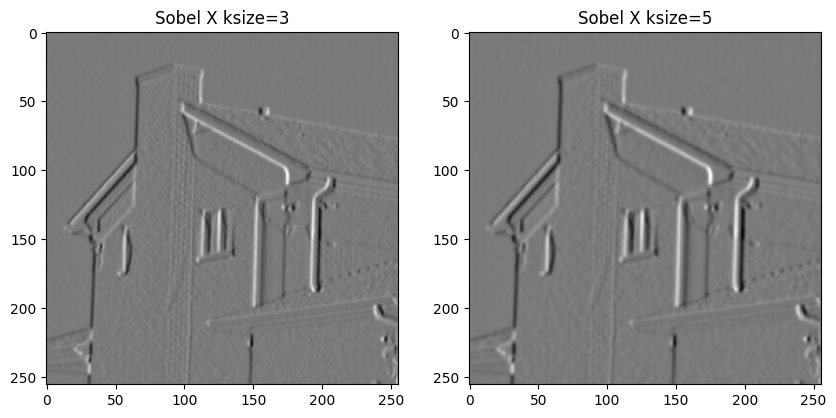

In [11]:
# TODO: apply Sobel in the X direction with ksize=3 and ksize=5, show side by side
sobel_x_3= cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobel_x_5= cv.Sobel(img, cv.CV_64F, 1, 0, ksize=5)
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.imshow(sobel_x_3, cmap="gray")
plt.title("Sobel X ksize=3")
plt.subplot(1,2,2)
plt.imshow(sobel_x_5, cmap="gray")
plt.title("Sobel X ksize=5")
plt.show()

**Question 5:** Describe the visible difference between the two. When would you choose 5×5 over 3×3?

*Your answer:* 

There is no big difference here but the image on the right is somewhat sharper while the image on the left is a bit blurry 

i would choose the 5*5 kernel size if i am applying sobel to a noisy image 

## Part 6: Gaussian, LoG & DoG

1. Blur the image with a Gaussian.
2. Apply the Laplacian on the blurred image (**LoG**).
3. Subtract two Gaussian blurs with different sigmas (**DoG**).

Then repeat the DoG with a **second pair of sigmas** (for example `(1, 2)` and `(2, 4)`) and compare.

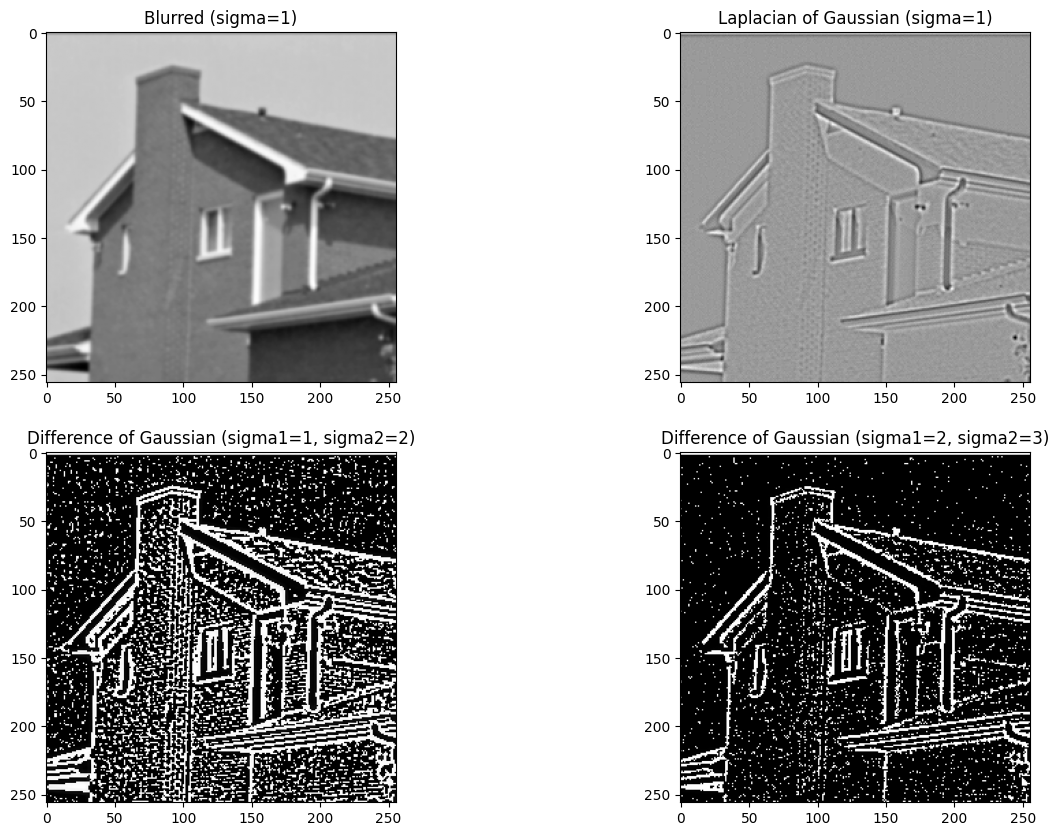

In [12]:
# TODO: blur, LoG, and DoG for the first sigma pair
blurred= cv.GaussianBlur(img, (5,5), 1)
log= cv.Laplacian(blurred, cv.CV_64F)
dog= cv.GaussianBlur(img, (5,5), 1) - cv.GaussianBlur(img, (5,5), 2)

# TODO: DoG for a second sigma pair
dog2= cv.GaussianBlur(img, (5,5), 2) - cv.GaussianBlur(img, (5,5), 3)
# TODO: show everything in one figure
plt.figure(figsize=(15, 10))
plt.subplot(2,2,1)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred (sigma=1)")
plt.subplot(2,2,2)
plt.imshow(log, cmap="gray")
plt.title("Laplacian of Gaussian (sigma=1)")
plt.subplot(2,2,3)
plt.imshow(dog, cmap="gray")
plt.title("Difference of Gaussian (sigma1=1, sigma2=2)")
plt.subplot(2,2,4)
plt.imshow(dog2, cmap="gray")
plt.title("Difference of Gaussian (sigma1=2, sigma2=3)")
plt.show()

**Question 6a:** Why do we blur before applying the Laplacian?

**Question 6b:** What changes in the DoG result when you increase the sigmas?

**Question 6c:** Which algorithm uses DoG for blob detection?

*Your answers:* 

It is definitely a wise decision to blur before using Laplacian since it is very sensitive to noise with it being the 2nd derivative 

the noise decreases when we increase the sigmas but also along with it fine details like the texture of the house blocks

SIFT uses DoG for blob detection where it builds a hierarchy of gaussian blurred images with different sigmas, subtract them and then compare each pixel in an image of this hierachy with its neigbhors from its image and the image above andddd the image below

## Part 7: Noise Experiment

Add noise to your image and see which filters survive.

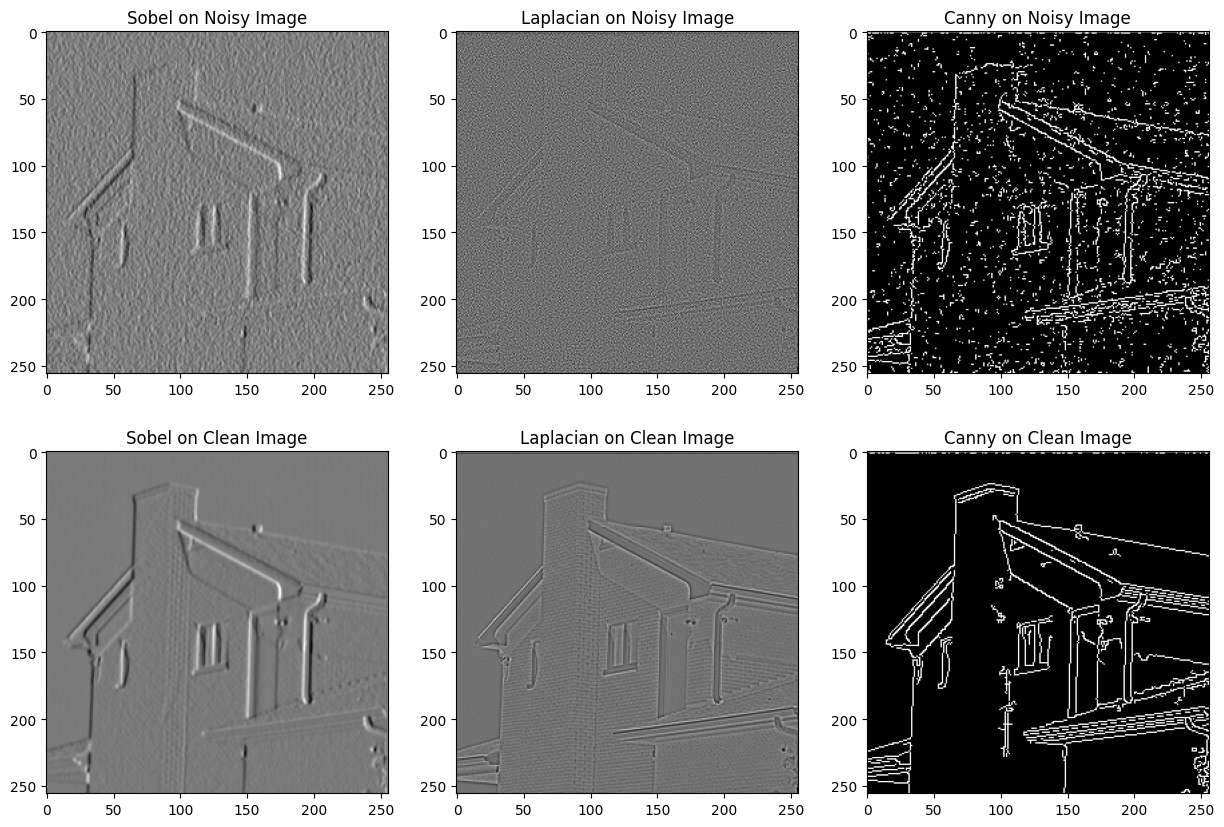

In [ ]:
# TODO: create a noisy copy of your image
# Hint: noise = np.random.normal(0, 25, img.shape)
#       noisy = np.clip(img + noise, 0, 255).astype(np.uint8)
noise =np.random.normal(0, 25, img.shape)
noisy =np.clip(img+noise, 0, 255).astype(np.uint8)
# TODO: apply Sobel (3x3), Laplacian and Canny on the NOISY image
sobel= cv.Sobel(noisy, cv.CV_64F, 1, 0, ksize=3)
laplacian_= cv.Laplacian(noisy, cv.CV_64F)
canny_= cv.Canny(noisy, 250, 300)
# TODO: show the 3 results next to the same 3 results from the clean image (2 rows x 3 columns)
plt.figure(figsize=(15, 10))
plt.subplot(2,3,1)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel on Noisy Image")
plt.subplot(2,3,2)
plt.imshow(laplacian_, cmap="gray")
plt.title("Laplacian on Noisy Image")
plt.subplot(2,3,3)
plt.imshow(canny_, cmap="gray")
plt.title("Canny on Noisy Image")
plt.subplot(2,3,4)
plt.imshow(cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3), cmap="gray")
plt.title("Sobel on Clean Image")
plt.subplot(2,3,5)
plt.imshow(cv.Laplacian(img, cv.CV_64F), cmap="gray")
plt.title("Laplacian on Clean Image")
plt.subplot(2,3,6)
plt.imshow(cv.Canny(img, 250, 300), cmap="gray")
plt.title("Canny on Clean Image")
plt.show()

**Question 7:** Which filter was hurt the most by noise, and which handled it best? Explain why, using what you know about derivatives and smoothing.

*Your answer:* 

Canny was the most damaged by noise despite its 5 step pipeline to give out best results what a shame 

Sobel handled it best because the edges are sharp but we all know Laplacian output is not intense it just simply outlines the edges without drama 

Sobel's kernel gives more weight to the central row or column to smooth the image while detecting the edges which explains why it remained standing against noise 

Laplacian being the second derivative makes it very sensitive to noise but i think the output here is clear despite the noise still so pass

I have no idea why the Canny image turned out this way if i had to speculate it would be because of the low values of both thresholds (ha8aiarha dlw washoof) but i am very disappointed i really liked the implementation of canny 

## Part 8: Final Comparison & Conclusion

Make one summary figure showing: Original, Sobel magnitude, Laplacian, Canny, LoG, DoG.

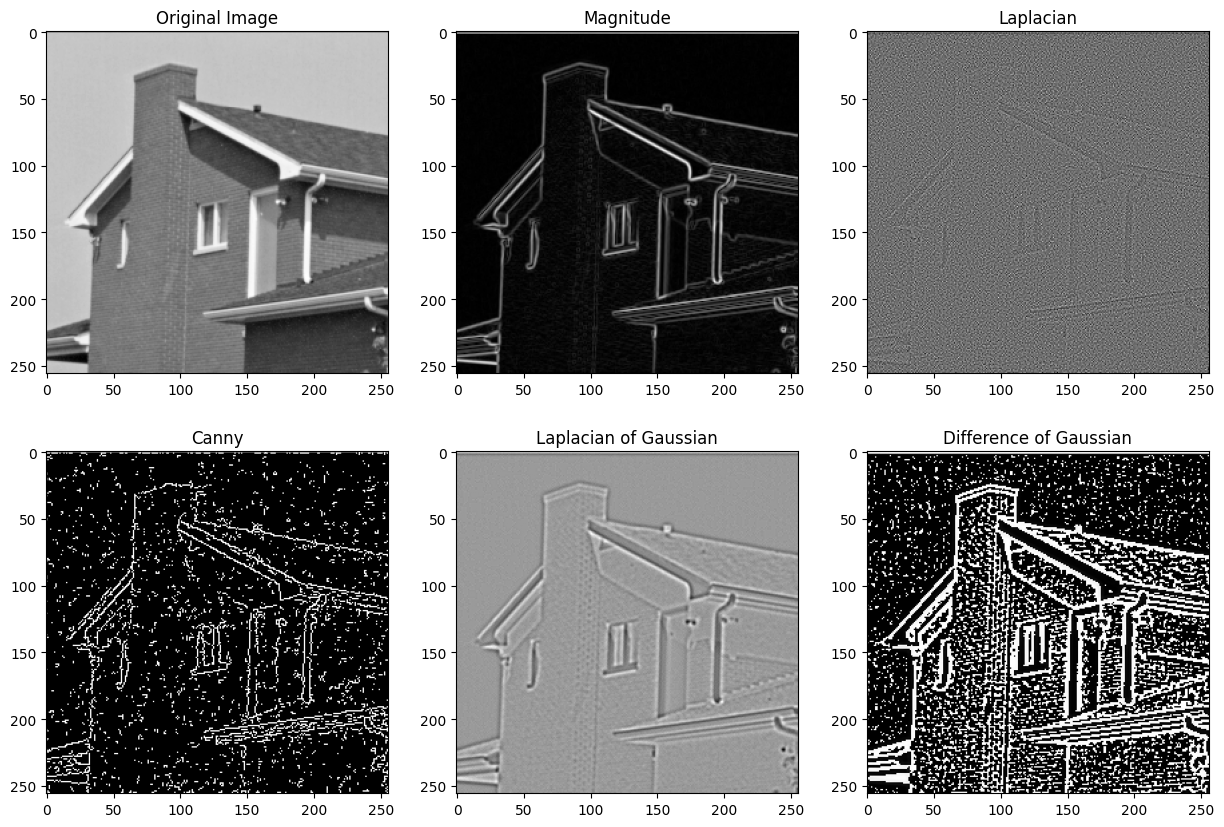

In [20]:
# TODO: 2x3 grid with all six results and titles
plt.figure(figsize=(15, 10))
plt.subplot(2,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.subplot(2,3,2)
plt.imshow(magnitude, cmap="gray")
plt.title("Magnitude")
plt.subplot(2,3,3)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian")
plt.subplot(2,3,4)
plt.imshow(canny, cmap="gray")
plt.title("Canny")
plt.subplot(2,3,5)
plt.imshow(log, cmap="gray")
plt.title("Laplacian of Gaussian")
plt.subplot(2,3,6)
plt.imshow(dog, cmap="gray")
plt.title("Difference of Gaussian")
plt.show()

**Final Question:** If you had to pick one method to detect the edges of objects in **your** image, which would you choose and why? Mention at least two trade-offs (noise, detail, thickness of edges, speed...).

*Your answer:* 

i would have really liked to use Canny 3shan el pipeline bta3ha kan 3agebni awi bs now i would pick sobel or log because both are clear about the edges and smootht (their methods invlove noise reduction) so gamed , thickness here is ideal i think and the details INSIDE the object are washed out a little but the outlines are highlighted. I think log is faster than sobel because sobel measures intensity of both directions first

i also really liked the output images of robert (the idea of intensity changes alond the diagonal is cool)
---

### Bonus (optional)
- Try your code on a second image with very different content (a face, text, a landscape) and describe what changed.
- Combine Sobel X and Y into the magnitude **without** using `np.sqrt` (hint: `cv2.magnitude`) and check that you get the same result.

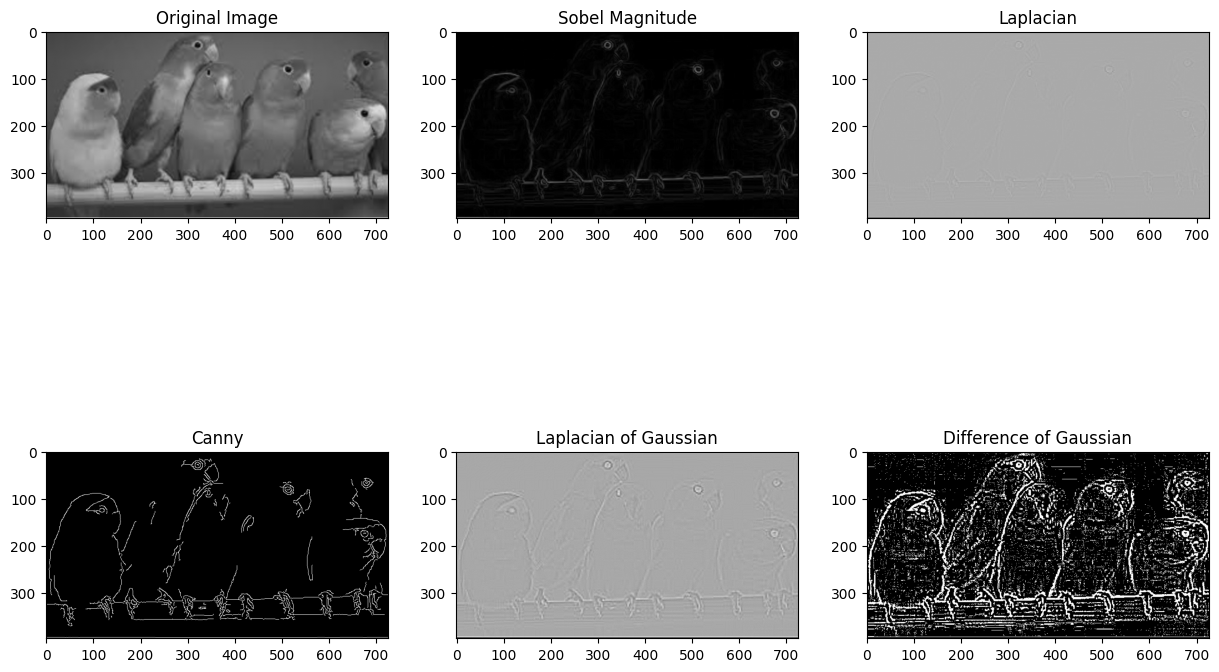

In [23]:
path=r"D:\SkyXperts-Vision-Course\Session4\Convolutional_Filters_Edge_Detection\images\birds.jpg"
img=cv.imread(path,0)
#sobel, laplacian, canny, log, dog
sobel_birds_x= cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobel_birds_y= cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)
sobel_birds_magnitude= cv.magnitude(sobel_birds_x, sobel_birds_y)
laplacian_birds= cv.Laplacian(img, cv.CV_64F)
canny_birds= cv.Canny(img, 50, 100)
log_birds= cv.Laplacian(cv.GaussianBlur(img, (5,5), 1), cv.CV_64F)
dog_birds= cv.GaussianBlur(img, (5,5), 1) - cv.GaussianBlur(img, (5,5), 2)
plt.figure(figsize=(15, 10))
plt.subplot(2,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.subplot(2,3,2)
plt.imshow(sobel_birds_magnitude, cmap="gray")
plt.title("Sobel Magnitude")
plt.subplot(2,3,3)
plt.imshow(laplacian_birds, cmap="gray")
plt.title("Laplacian")
plt.subplot(2,3,4)
plt.imshow(canny_birds, cmap="gray")
plt.title("Canny")
plt.subplot(2,3,5)
plt.imshow(log_birds, cmap="gray")
plt.title("Laplacian of Gaussian")
plt.subplot(2,3,6)
plt.imshow(dog_birds, cmap="gray")
plt.title("Difference of Gaussian")
plt.show()


I think choosing the right edge detection filter is subjective to each sample image since here the results of the filters differ significantly from the results on the house image 